<img src="./logo_UNSAM.png" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº7
#### Serena Saggion


dict_keys(['__header__', '__version__', '__globals__', 'ecg_lead', 'qrs_pattern1', 'heartbeat_pattern1', 'heartbeat_pattern2', 'qrs_detections'])


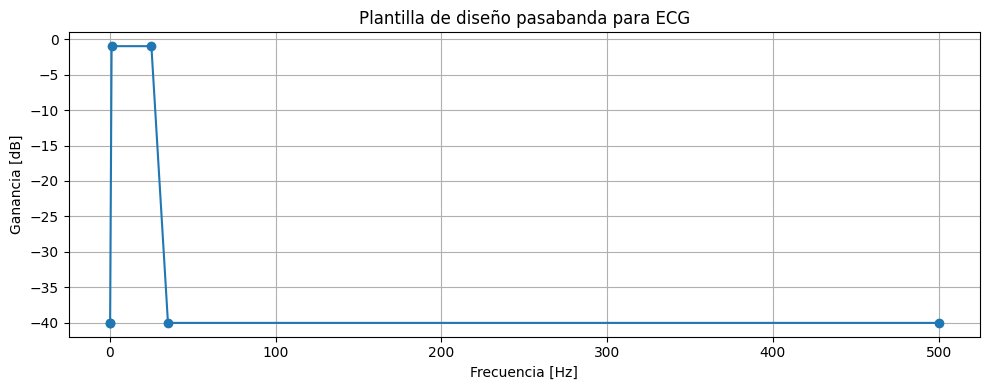

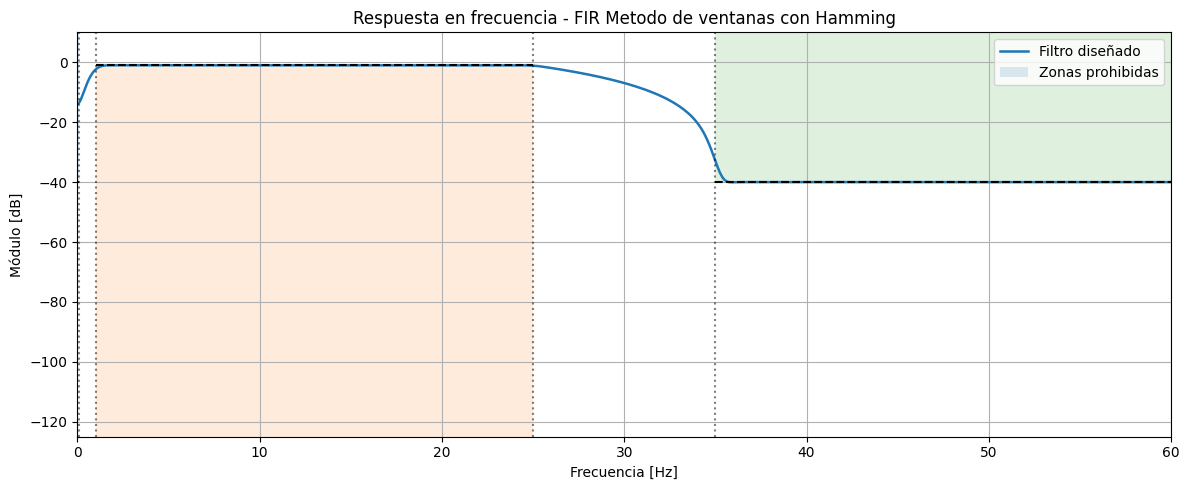

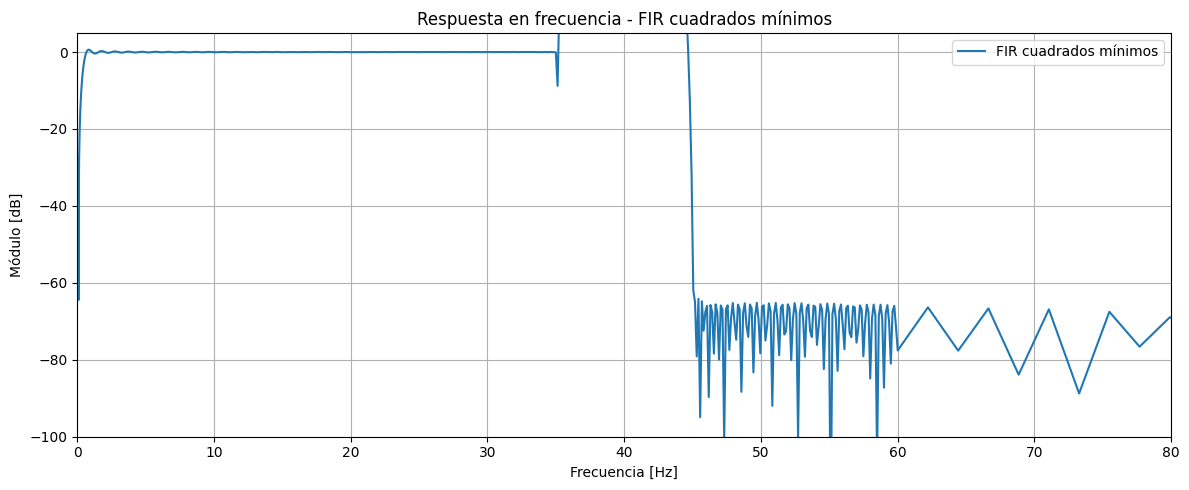

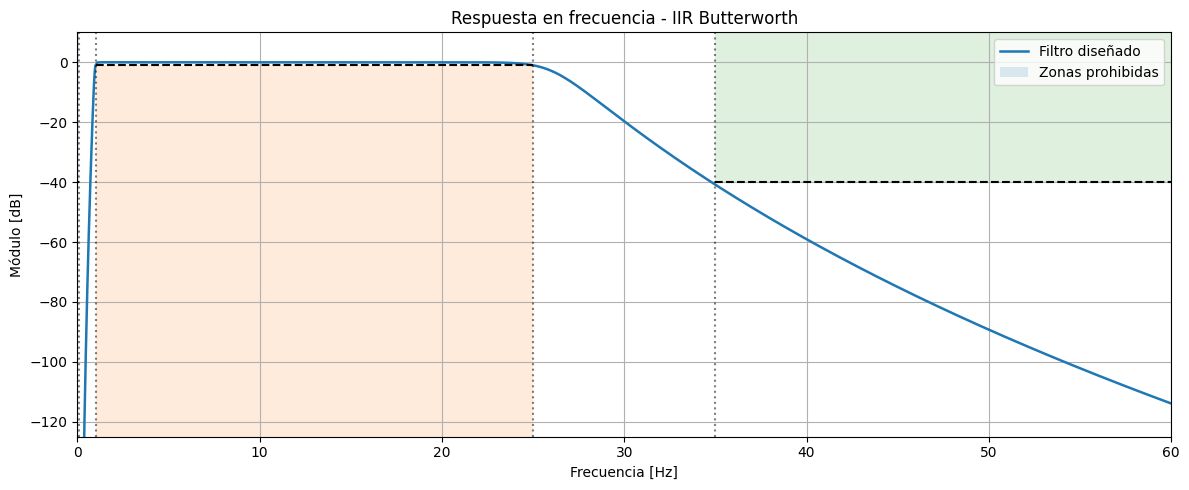

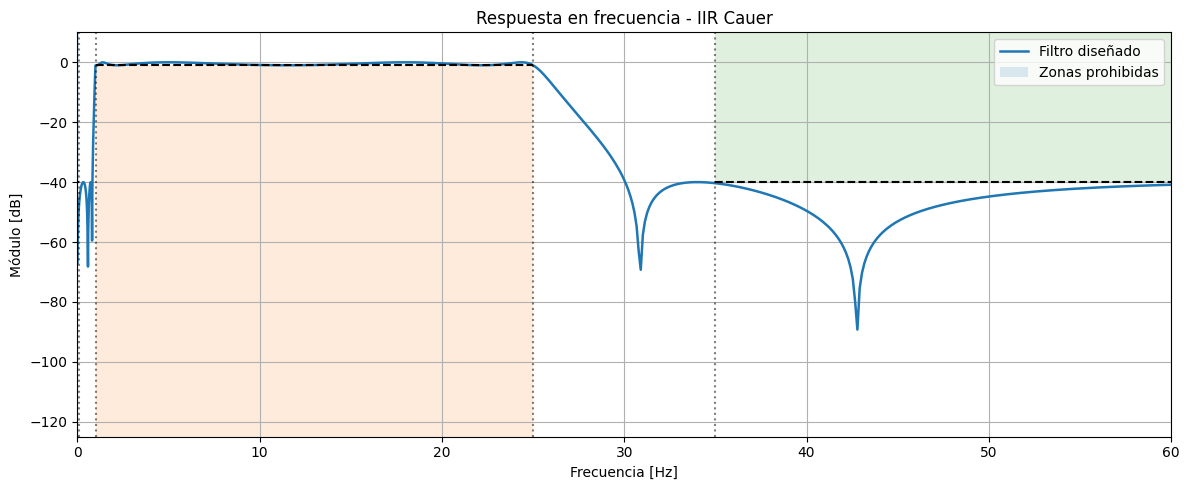

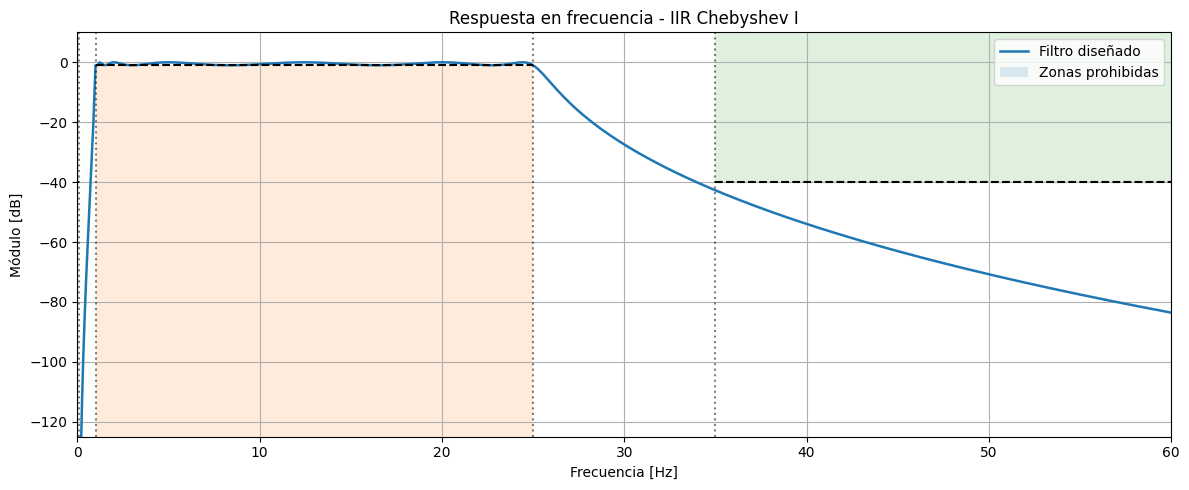

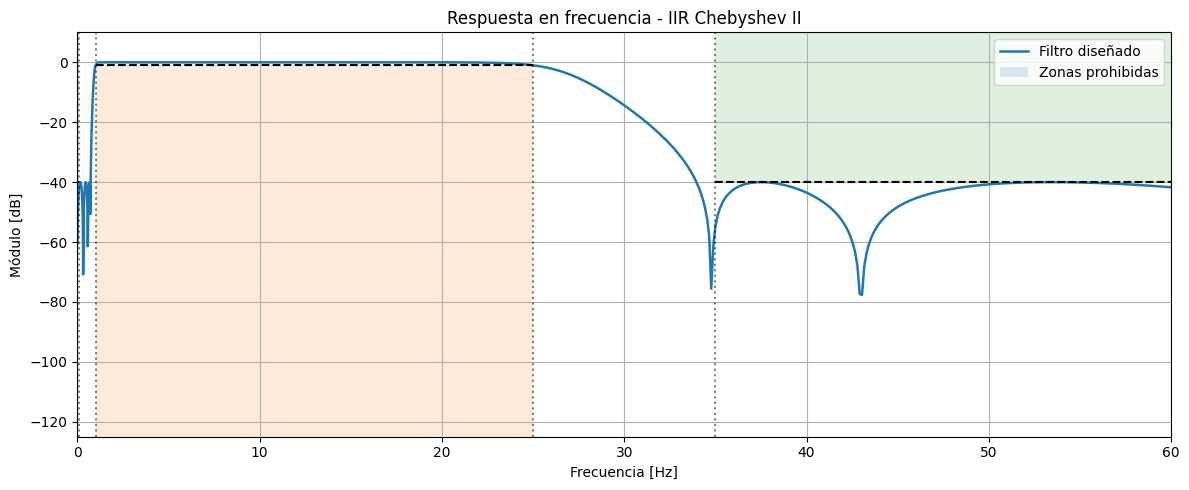

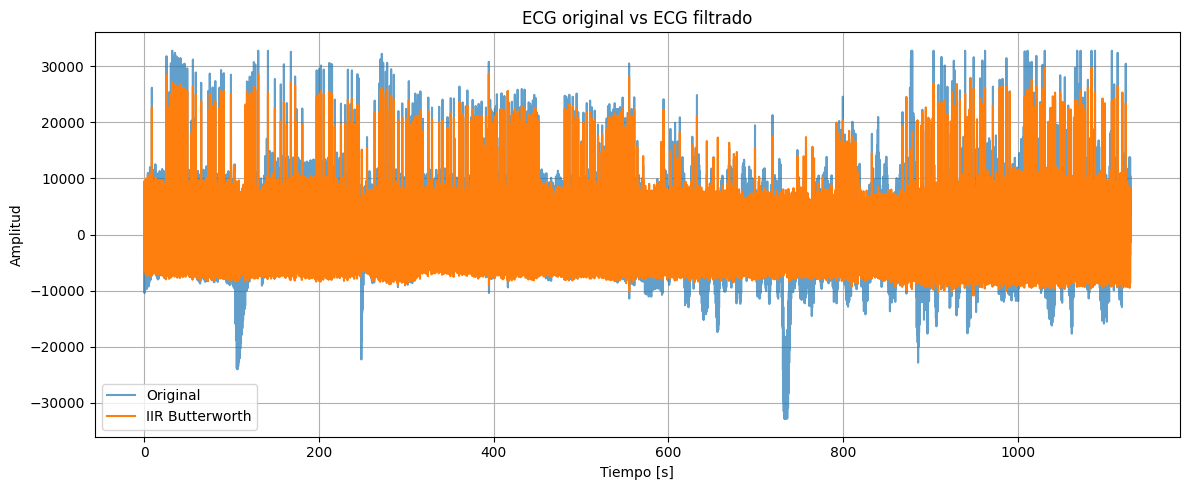

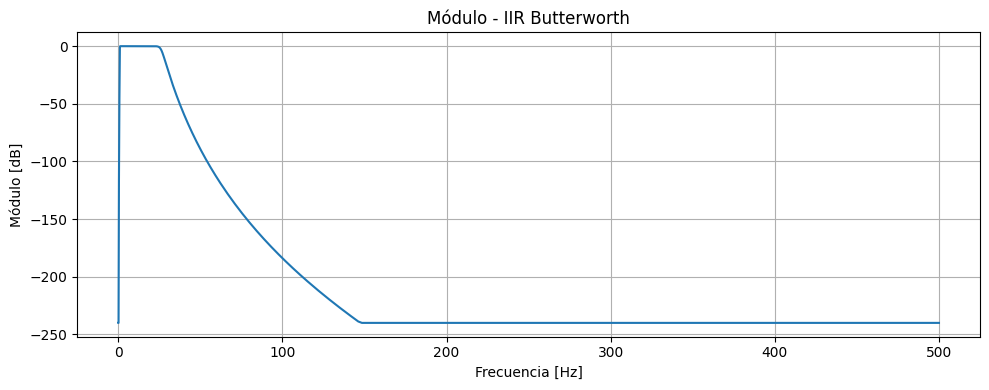

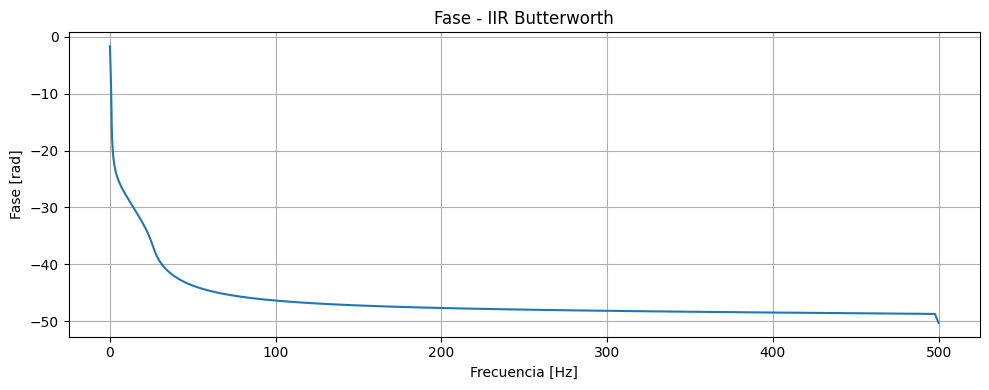

C:\Users\sere2\AppData\Local\Temp\ipykernel_23932\471253935.py:281: RuntimeWarning: invalid value encountered in divide
  gd = -np.diff(fase) / np.diff(Omega)


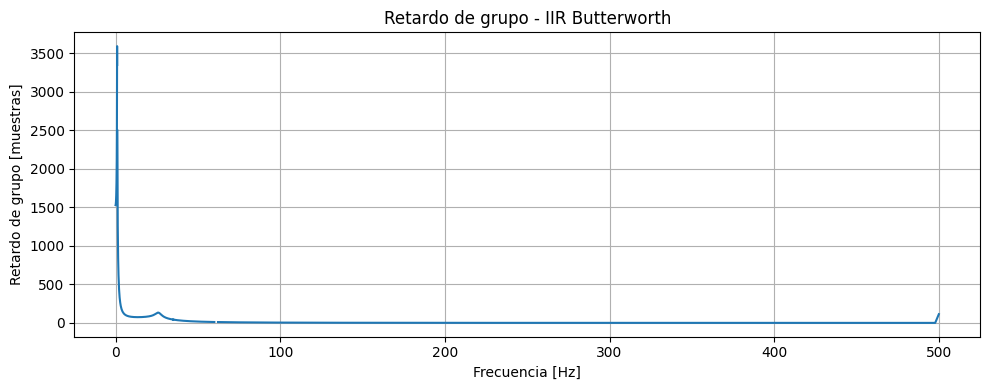

C:\Users\sere2\AppData\Roaming\Python\Python313\site-packages\scipy\signal\_filter_design.py:1230: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


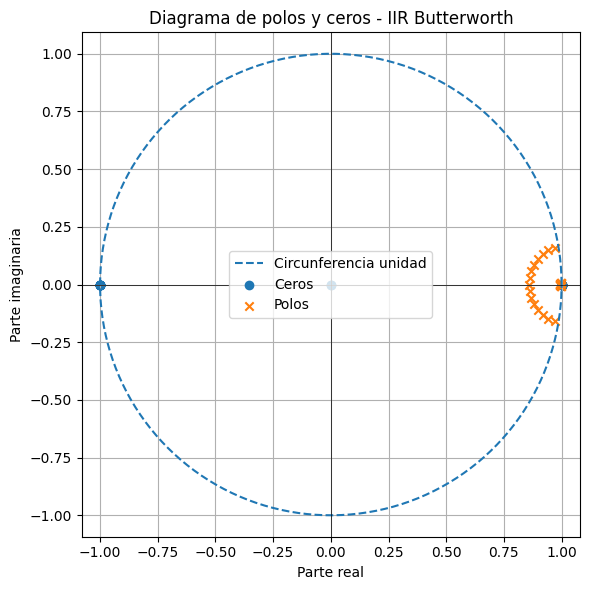

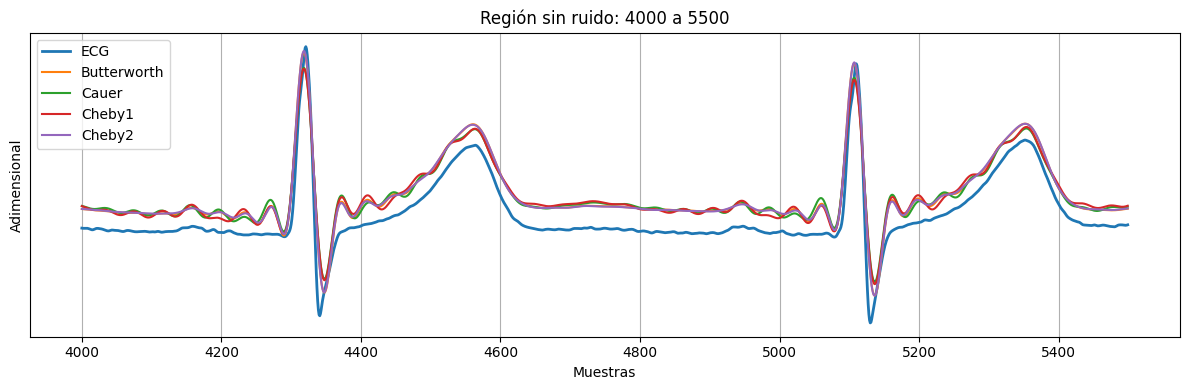

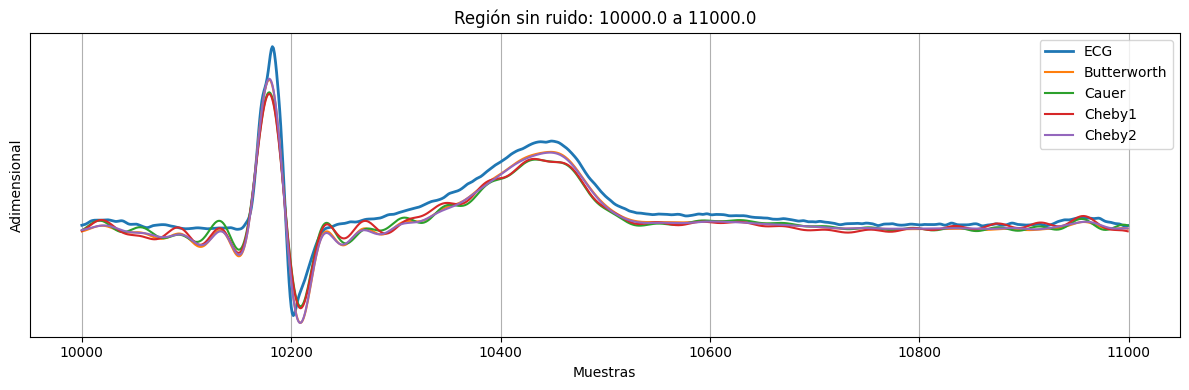

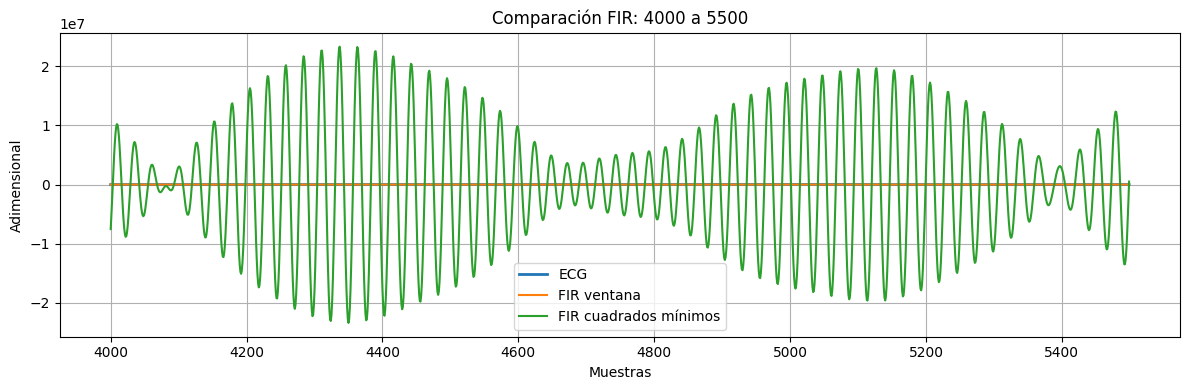

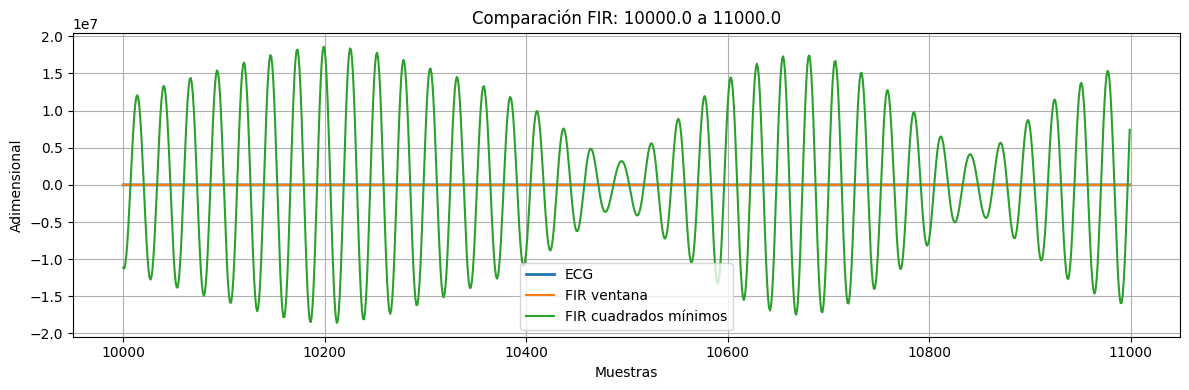

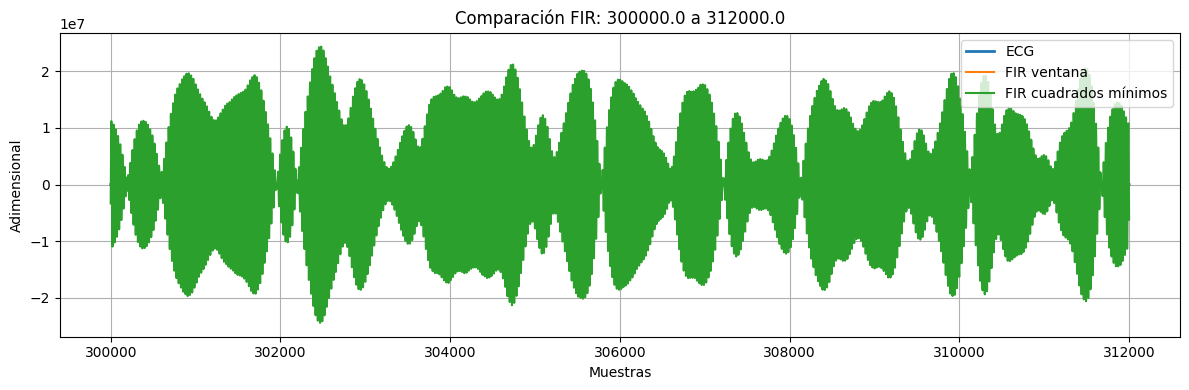

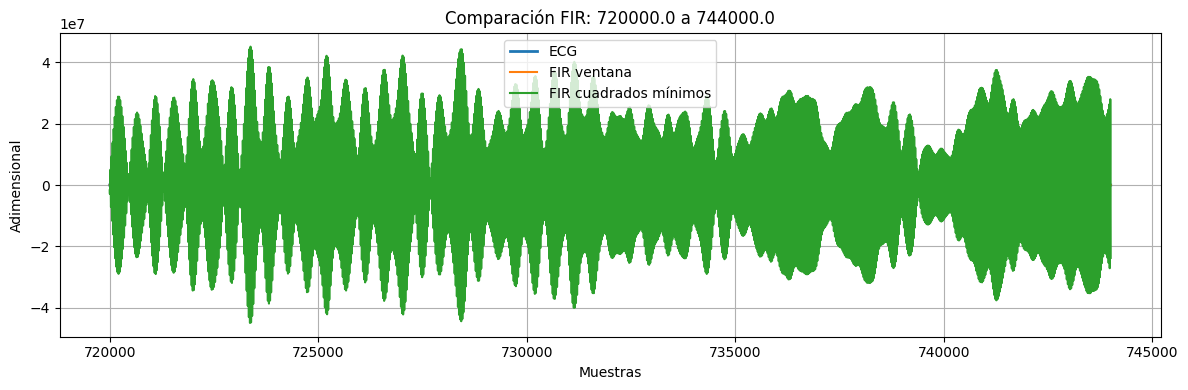

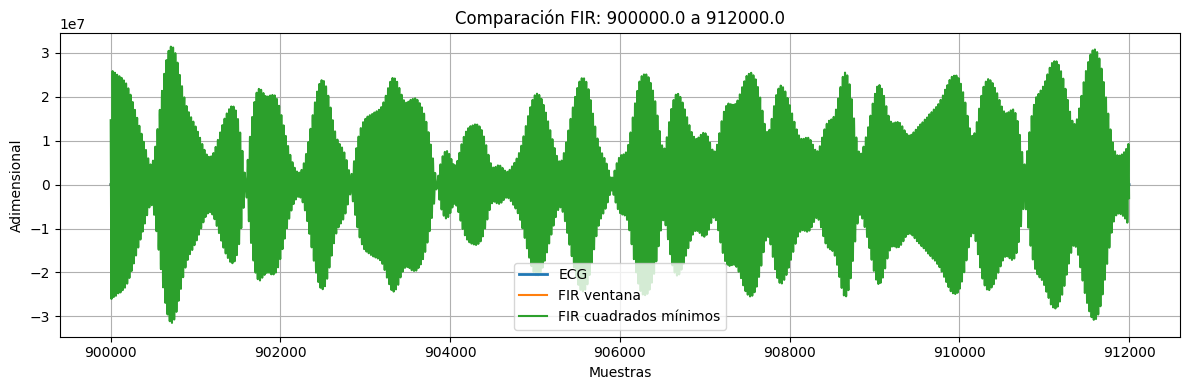

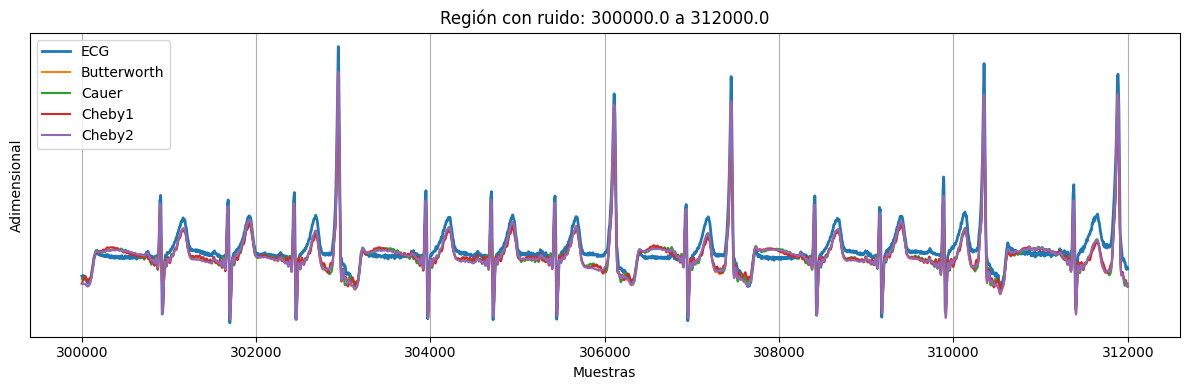

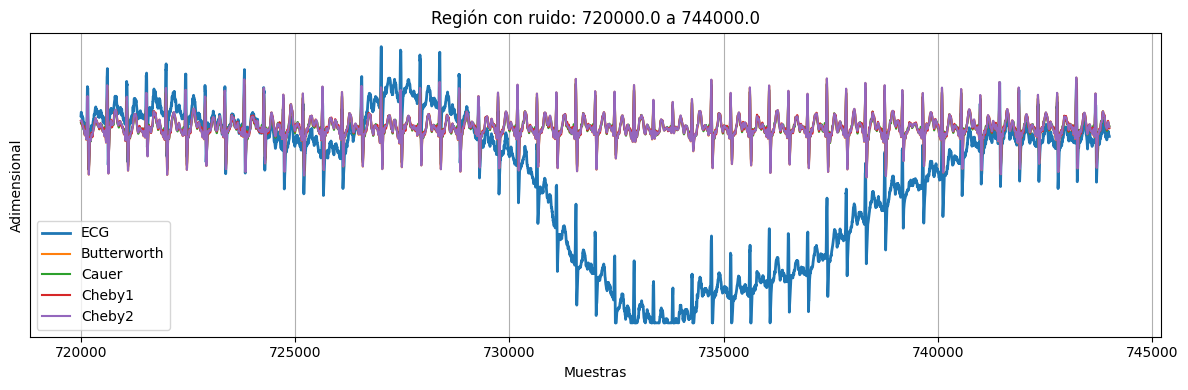

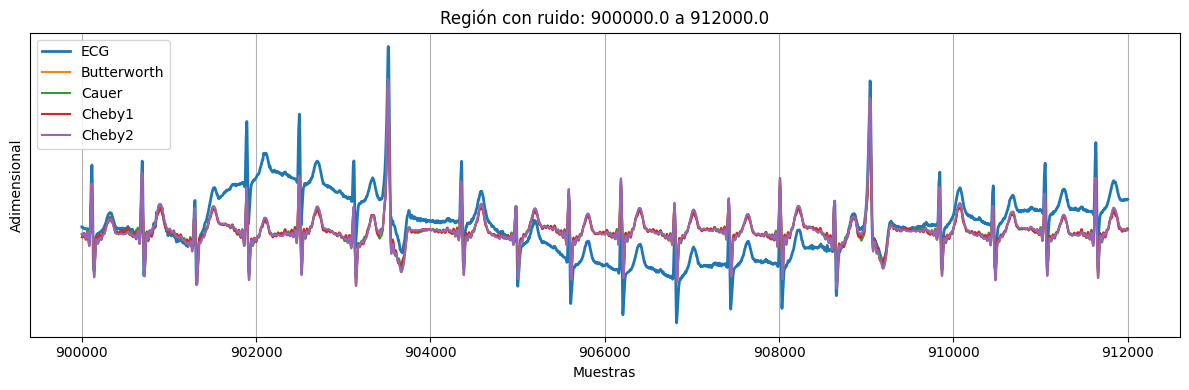

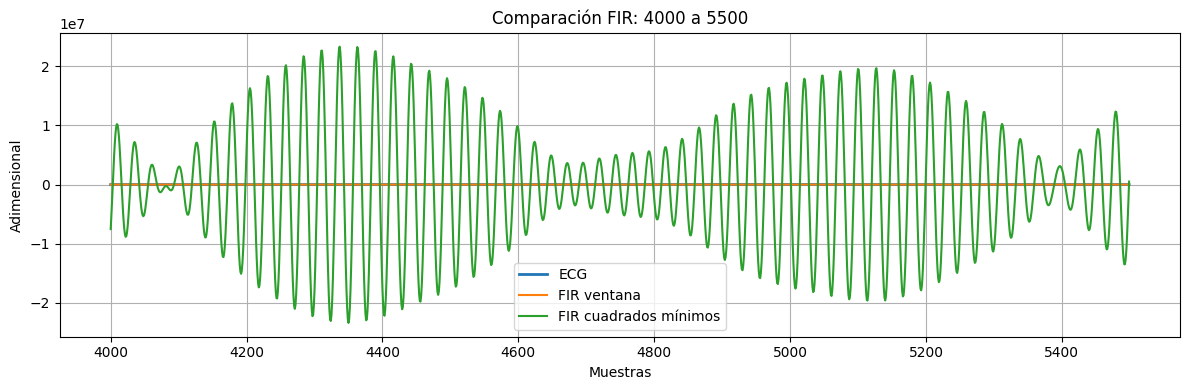

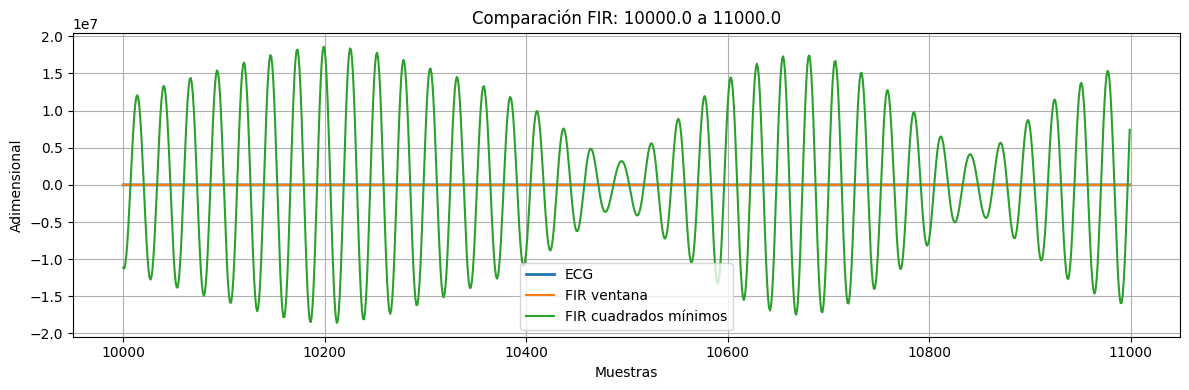

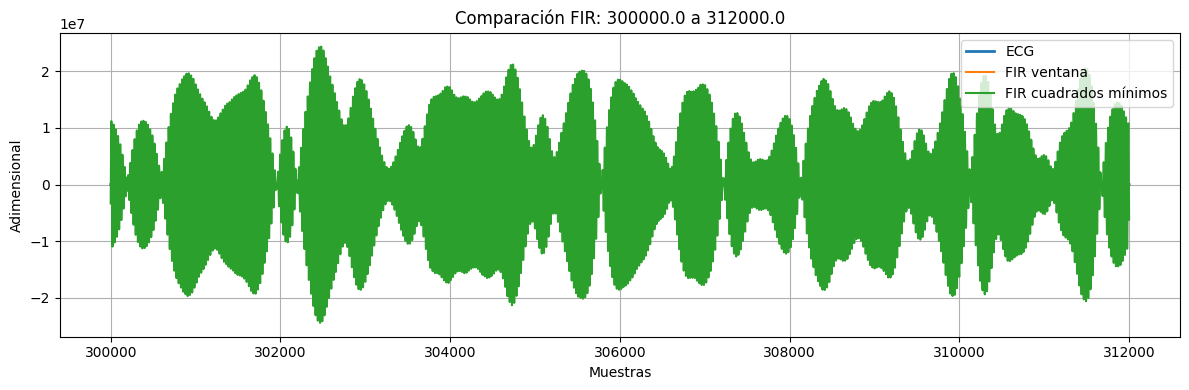

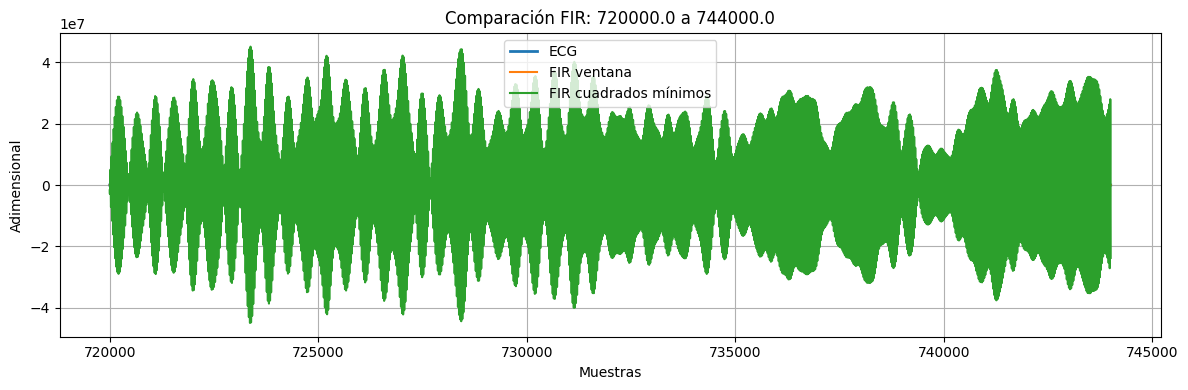

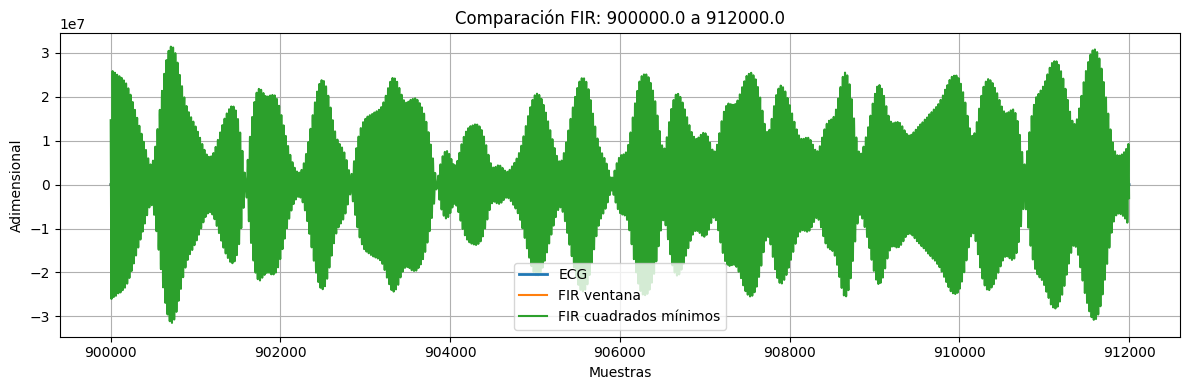

In [2]:
#%% TS7

from scipy import signal
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

#%% CARGA DEL ECG

mat_struct = sio.loadmat("./ECG_TP4.mat")
print(mat_struct.keys())

ecg = mat_struct["ecg_lead"].flatten()

fs = 1000
fn = fs / 2
cant_muestras = len(ecg)

t = np.arange(cant_muestras) / fs

#%% PLANTILLA DE DISEÑO

ripple = 1       # dB
atenuacion = 40  # dB

ws1 = 0.1   # Hz
wp1 = 1     # Hz
wp2 = 25    # Hz
ws2 = 35    # Hz

gpass = ripple
gstop = atenuacion

# Plantilla normalizada a Nyquist en dB
frecs = np.array([0.0, ws1, wp1, wp2, ws2, fn]) / fn

gains_db = np.array([
    -atenuacion,
    -atenuacion,
    -ripple,
    -ripple,
    -atenuacion,
    -atenuacion
])

# Convertimos a veces para funciones FIR tipo firwin2
gains = 10**(gains_db / 20)

plt.figure(figsize=(10,4), tight_layout=True)
plt.plot(frecs * fn, gains_db, "o-")
plt.title("Plantilla de diseño pasabanda para ECG")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Ganancia [dB]")
plt.grid(True)
plt.show()

#%% VECTOR DE FRECUENCIAS PARA GRAFICAR

ww = np.concatenate([
    np.logspace(-2, 0, 200),
    np.linspace(1, 35, 300),
    np.linspace(35, 60, 200),
    np.linspace(60, fs/2, 200)
])

#%% FUNCIÓN PARA GRAFICAR RESPUESTA + PLANTILLA

def graficar_respuesta_fir(b, titulo):
    w, h = signal.freqz(b, worN=ww, fs=fs)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    fig, ax = plt.subplots(figsize=(12,5), tight_layout=True)
    ax.plot(w, modulo_db, label="Filtro diseñado", linewidth=1.8)

    piso = -125
    techo = 10

    # zonas prohibidas
    ax.fill_between([0, ws1], -gstop, techo, alpha=0.15, label="Zonas prohibidas")
    ax.plot([0, ws1], [-gstop, -gstop], "k--")

    ax.fill_between([wp1, wp2], piso, -gpass, alpha=0.15)
    ax.plot([wp1, wp2], [-gpass, -gpass], "k--")

    ax.fill_between([ws2, fs/2], -gstop, techo, alpha=0.15)
    ax.plot([ws2, fs/2], [-gstop, -gstop], "k--")

    ax.axvline(ws1, color="k", linestyle=":", alpha=0.5)
    ax.axvline(wp1, color="k", linestyle=":", alpha=0.5)
    ax.axvline(wp2, color="k", linestyle=":", alpha=0.5)
    ax.axvline(ws2, color="k", linestyle=":", alpha=0.5)

    ax.set_title(titulo)
    ax.set_xlabel("Frecuencia [Hz]")
    ax.set_ylabel("Módulo [dB]")
    ax.set_xlim(0, 60)
    ax.set_ylim(piso, techo)
    ax.grid(True)
    ax.legend()
    plt.show()


def graficar_respuesta_iir(sos, titulo):
    w, h = signal.sosfreqz(sos, worN=ww, fs=fs)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    fig, ax = plt.subplots(figsize=(12,5), tight_layout=True)
    ax.plot(w, modulo_db, label="Filtro diseñado", linewidth=1.8)

    piso = -125
    techo = 10

    ax.fill_between([0, ws1], -gstop, techo, alpha=0.15, label="Zonas prohibidas")
    ax.plot([0, ws1], [-gstop, -gstop], "k--")

    ax.fill_between([wp1, wp2], piso, -gpass, alpha=0.15)
    ax.plot([wp1, wp2], [-gpass, -gpass], "k--")

    ax.fill_between([ws2, fs/2], -gstop, techo, alpha=0.15)
    ax.plot([ws2, fs/2], [-gstop, -gstop], "k--")

    ax.axvline(ws1, color="k", linestyle=":", alpha=0.5)
    ax.axvline(wp1, color="k", linestyle=":", alpha=0.5)
    ax.axvline(wp2, color="k", linestyle=":", alpha=0.5)
    ax.axvline(ws2, color="k", linestyle=":", alpha=0.5)

    ax.set_title(titulo)
    ax.set_xlabel("Frecuencia [Hz]")
    ax.set_ylabel("Módulo [dB]")
    ax.set_xlim(0, 60)
    ax.set_ylim(piso, techo)
    ax.grid(True)
    ax.legend()
    plt.show()

#%% FIR 1 - METODO DE VENTANAS CON VENTANA HAMMING

cant_coef = 2001

b_firwin2 = signal.firwin2(
    cant_coef,
    frecs,
    gains,
    window="hamming"
)

N = len(b_firwin2)
demora = int((N - 1) / 2)

graficar_respuesta_fir(
    b_firwin2,
    "Respuesta en frecuencia - FIR Metodo de ventanas con Hamming"
)

ecg_firwin2 = signal.lfilter(b_firwin2, [1], ecg)

#%% FIR 2 - CUADRADOS MÍNIMOS

numtapsc = 2001

ws1f = 0.2
wp1f = 0.5
wp2f = 35
ws2f = 45

b_cuadradosmin = signal.firls(
    numtapsc,
    bands=[0, ws1f, wp1f, wp2f, ws2f, fs/2],
    desired=[0, 0, 1, 1, 0, 0],
    weight=[2, 1, 2],
    fs=fs
)

demora_c = int((numtapsc - 1) / 2)

w_c, h_c = signal.freqz(b_cuadradosmin, worN=ww, fs=fs)
modulo_dbc = 20*np.log10(np.abs(h_c) + 1e-12)

plt.figure(figsize=(12,5), tight_layout=True)
plt.plot(w_c, modulo_dbc, label="FIR cuadrados mínimos")
plt.title("Respuesta en frecuencia - FIR cuadrados mínimos")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Módulo [dB]")
plt.xlim(0, 80)
plt.ylim(-100, 5)
plt.grid(True)
plt.legend()
plt.show()

ECG_f_cuad = signal.lfilter(b_cuadradosmin, [1], ecg)


#%% IIR - BUTTERWORTH, CAUER, CHEBY1, CHEBY2

wp = [wp1, wp2]
ws = [ws1, ws2]

sos_butter = signal.iirdesign(
    wp, ws,
    gpass, gstop,
    ftype="butter",
    output="sos",
    fs=fs
)

sos_cauer = signal.iirdesign(
    wp, ws,
    gpass, gstop,
    ftype="ellip",
    output="sos",
    fs=fs
)

sos_cheby1 = signal.iirdesign(
    wp, ws,
    gpass, gstop,
    ftype="cheby1",
    output="sos",
    fs=fs
)

sos_cheby2 = signal.iirdesign(
    wp, ws,
    gpass, gstop,
    ftype="cheby2",
    output="sos",
    fs=fs
)

graficar_respuesta_iir(sos_butter, "Respuesta en frecuencia - IIR Butterworth")
graficar_respuesta_iir(sos_cauer, "Respuesta en frecuencia - IIR Cauer")
graficar_respuesta_iir(sos_cheby1, "Respuesta en frecuencia - IIR Chebyshev I")
graficar_respuesta_iir(sos_cheby2, "Respuesta en frecuencia - IIR Chebyshev II")

#%% FILTRADO IIR CON FILTFILT

ecg_butter = signal.sosfiltfilt(sos_butter, ecg)
ecg_cauer = signal.sosfiltfilt(sos_cauer, ecg)
ecg_cheby1 = signal.sosfiltfilt(sos_cheby1, ecg)
ecg_cheby2 = signal.sosfiltfilt(sos_cheby2, ecg)

#%% ECG ORIGINAL VS FILTRADO GENERAL

plt.figure(figsize=(12,5), tight_layout=True)
plt.plot(t, ecg, label="Original", alpha=0.7)
plt.plot(t, ecg_butter, label="IIR Butterworth")
plt.title("ECG original vs ECG filtrado")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()
plt.show()

#%% RESPUESTA EN FRECUENCIA, FASE Y RETARDO DE GRUPO DE UN IIR

sos_elegido = sos_butter
nombre_elegido = "Butterworth"

f, H = signal.sosfreqz(sos_elegido, worN=ww, fs=fs)

modulo_db = 20 * np.log10(np.maximum(np.abs(H), 1e-12))
fase = np.unwrap(np.angle(H))

plt.figure(figsize=(10,4), tight_layout=True)
plt.plot(f, modulo_db)
plt.title(f"Módulo - IIR {nombre_elegido}")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Módulo [dB]")
plt.grid(True)
plt.show()

plt.figure(figsize=(10,4), tight_layout=True)
plt.plot(f, fase)
plt.title(f"Fase - IIR {nombre_elegido}")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Fase [rad]")
plt.grid(True)
plt.show()

Omega = 2 * np.pi * f / fs
gd = -np.diff(fase) / np.diff(Omega)
gd = np.append(gd[0], gd)

plt.figure(figsize=(10,4), tight_layout=True)
plt.plot(f, gd)
plt.title(f"Retardo de grupo - IIR {nombre_elegido}")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Retardo de grupo [muestras]")
plt.grid(True)
plt.show()

#%% DIAGRAMA DE POLOS Y CEROS IIR

z, p, k = signal.sos2zpk(sos_elegido)

plt.figure(figsize=(6,6), tight_layout=True)

theta = np.linspace(0, 2*np.pi, 500)
plt.plot(np.cos(theta), np.sin(theta), "--", label="Circunferencia unidad")

plt.scatter(np.real(z), np.imag(z), marker="o", label="Ceros")
plt.scatter(np.real(p), np.imag(p), marker="x", label="Polos")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.title(f"Diagrama de polos y ceros - IIR {nombre_elegido}")
plt.xlabel("Parte real")
plt.ylabel("Parte imaginaria")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

#%% REGIONES DE INTERÉS SIN RUIDO
# Sirven para verificar que el filtro no deforme mucho el ECG

regs_sin_ruido = (
    [4000, 5500],
    [10e3, 11e3],
)

for ii in regs_sin_ruido:

    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras - demora, ii[1]]),
        dtype="uint"
    )

    plt.figure(figsize=(12,4), tight_layout=True)
    plt.plot(zoom_region, ecg[zoom_region], label="ECG", linewidth=2)
    plt.plot(zoom_region, ecg_butter[zoom_region], label="Butterworth")
    plt.plot(zoom_region, ecg_cauer[zoom_region], label="Cauer")
    plt.plot(zoom_region, ecg_cheby1[zoom_region], label="Cheby1")
    plt.plot(zoom_region, ecg_cheby2[zoom_region], label="Cheby2")

    plt.title("Región sin ruido: " + str(ii[0]) + " a " + str(ii[1]))
    plt.ylabel("Adimensional")
    plt.xlabel("Muestras")
    plt.grid(True)
    plt.legend()
    plt.gca().set_yticks(())
    plt.show()


#%% Comparación FIR en regiones

regs_interes = (
    [4000, 5500],
    [10e3, 11e3],
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs,
)

for ii in regs_interes:

    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras - max(demora, demora_c), ii[1]]),
        dtype="uint"
    )

    plt.figure(figsize=(12,4), tight_layout=True)
    plt.plot(zoom_region, ecg[zoom_region], label="ECG", linewidth=2)
    plt.plot(zoom_region, ecg_firwin2[zoom_region + demora], label="FIR ventana")
    plt.plot(zoom_region, ECG_f_cuad[zoom_region + demora_c], label="FIR cuadrados mínimos")

    plt.title("Comparación FIR: " + str(ii[0]) + " a " + str(ii[1]))
    plt.xlabel("Muestras")
    plt.ylabel("Adimensional")
    plt.grid(True)
    plt.legend()
    plt.show()
#%% REGIONES DE INTERÉS CON RUIDO
# Sirven para verificar que el filtro atenúe las interferencias

regs_con_ruido = (
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs,
)

for ii in regs_con_ruido:

    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras - demora, ii[1]]),
        dtype="uint"
    )

    plt.figure(figsize=(12,4), tight_layout=True)
    plt.plot(zoom_region, ecg[zoom_region], label="ECG", linewidth=2)
    plt.plot(zoom_region, ecg_butter[zoom_region], label="Butterworth")
    plt.plot(zoom_region, ecg_cauer[zoom_region], label="Cauer")
    plt.plot(zoom_region, ecg_cheby1[zoom_region], label="Cheby1")
    plt.plot(zoom_region, ecg_cheby2[zoom_region], label="Cheby2")
    plt.title("Región con ruido: " + str(ii[0]) + " a " + str(ii[1]))
    plt.ylabel("Adimensional")
    plt.xlabel("Muestras")
    plt.grid(True)
    plt.legend()
    plt.gca().set_yticks(())
    plt.show()
    
#%% Comparación FIR en regiones

regs_interes = (
    [4000, 5500],
    [10e3, 11e3],
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs,
)

for ii in regs_interes:

    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras - max(demora, demora_c), ii[1]]),
        dtype="uint"
    )

    plt.figure(figsize=(12,4), tight_layout=True)
    plt.plot(zoom_region, ecg[zoom_region], label="ECG", linewidth=2)
    plt.plot(zoom_region, ecg_firwin2[zoom_region + demora], label="FIR ventana")
    plt.plot(zoom_region, ECG_f_cuad[zoom_region + demora_c], label="FIR cuadrados mínimos")

    plt.title("Comparación FIR: " + str(ii[0]) + " a " + str(ii[1]))
    plt.xlabel("Muestras")
    plt.ylabel("Adimensional")
    plt.grid(True)
    plt.legend()
    plt.show()